# Receiver geolocation from propeller-aircraft Doppler signatures and ADS-B trajectories

*Implementation and synthetic validation*

---

**Abstract.** Light aircraft radiate a narrow-band tone at the propeller blade-passage frequency. To a stationary
microphone, the received frequency follows a Doppler curve whose shape is fixed by three quantities: the aircraft's
speed, its closest-approach distance and its time of closest approach [1]. Each aircraft equipped with ADS-B
broadcasts its own trajectory. Comparing several observed curves with those trajectories therefore constrains where
the microphone was. We describe an implementation of this inversion with five stages:

- tonal ridge extraction from a whitened spectrogram;
- retarded-time Doppler fitting of each flyover;
- enumeration of closest approaches on a terrain-following grid;
- epoch-consistency and "silence" constraints;
- maximum-likelihood refinement with nuisance atmospheric parameters.

We test it on twelve synthetic scenarios. In each, the estimator assumes the wrong atmosphere and knows the
recording start time only to ±15 min. In eleven scenarios the receiver is located within 13–87 m (median 29 m),
and the clock is recovered to about 1 s. In the twelfth scenario only one usable flyover is present, so the
position is under-determined; the estimator flags it as ambiguous.

**Contents.** 1 Introduction · 2 Signal model · 3 Synthetic scenario · 4 Method · 5 Results ·
6 Discussion and limitations · 7 Application to recorded data · References

## 1. Introduction

The rotating blades of a propeller produce periodic pressure fluctuations at the blade-passage frequency (BPF)
$f_0 = B\,\Omega/60$, where $B$ is the number of blades and $\Omega$ the shaft speed in rpm, together with its
harmonics $h f_0$ [3]. Typical general-aviation values give tones between about 50 and 150 Hz:

- a two-blade propeller at 2 400 rpm radiates at 80 Hz;
- a four-blade turboprop propeller at 1 650 rpm radiates at 110 Hz.

These tones propagate well over kilometre ranges. In a long-window spectrogram they appear as thin lines that
sweep downward as the aircraft passes, even when they are inaudible in the recording.

Ferguson [1] showed that the time–frequency curve observed by a single sensor determines the aircraft's speed,
its height at closest approach and the source frequency; Ferguson and Quinn [2] refined the estimation. The
inverse use of the same physics is to treat the aircraft trajectory as known and solve for the observer. Aircraft
positions are available from ADS-B, which is openly archived (e.g. [5]).

This notebook documents the `doppler_geo` engine stage by stage. Every number and figure below is computed when
the notebook is executed. The evaluation uses synthetic scenarios with known ground truth, and the method should
only be applied to recordings one is entitled to analyse. All aircraft in the scenarios are fictitious, with
callsigns prefixed `SIM`.

In [1]:
%matplotlib inline
import sys, time, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
from IPython.display import display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import doppler_geo as dg
from doppler_geo import viz
from doppler_geo.geo import haversine_m
from doppler_geo.pipeline import atmosphere_of
from doppler_geo.synth import make_world, render_audio, synth_adsb

viz.use_style()
matplotlib.rcParams["figure.dpi"] = 150
pd.set_option("display.precision", 2)
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)


def show(fig, stem):
    viz.save(fig, FIGDIR / stem)   # PDF + 300-dpi PNG next to the notebook
    display(fig)


print(f"doppler_geo {dg.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}")

doppler_geo 0.2.0 | numpy 2.2.6 | matplotlib 3.10.3


## 2. Signal model

### 2.1 Retarded-time Doppler shift

Let $\tau$ be the time at which sound is emitted and $t$ the time at which it reaches the receiver. In still air
with sound speed $c$, the two are related by the slant range $R(\tau)$ at emission:

$$ t = \tau + \frac{R(\tau)}{c}. \tag{1} $$

Phase is conserved along the ray, so the received frequency is the emitted frequency divided by
$\mathrm{d}t/\mathrm{d}\tau$:

$$ f(t) = \frac{f_0}{\mathrm{d}t/\mathrm{d}\tau} = \frac{f_0\,c}{c + v_r(\tau)}, \qquad v_r = \frac{\mathrm{d}R}{\mathrm{d}\tau}. \tag{2} $$

The radial velocity $v_r$ is positive for a receding source and is evaluated at the emission time. Evaluating
the geometry at the arrival time instead (the *instantaneous* model) produces a symmetric curve. That curve is
offset and distorted by up to several hertz near closest approach (Fig. 1c, d).

### 2.2 Straight, constant-speed flyby

Consider a straight path flown at speed $v$ that passes at minimum slant distance $d$ at emission time
$\tau_\mathrm{ca}$. Then $R^2 = d^2 + v^2(\tau-\tau_\mathrm{ca})^2$. Substituting into (1) gives a quadratic in
$\tau$, whose causal root is

$$ \tau - \tau_\mathrm{ca} = \frac{c^2 T - \sqrt{c^2 v^2 T^2 + (c^2 - v^2)\,d^2}}{c^2 - v^2}, \qquad T = t - \tau_\mathrm{ca}. \tag{3} $$

Equations (2)–(3) describe the received curve with four parameters $(f_0, v, d, \tau_\mathrm{ca})$. Each one
is visible in the curve:

- the relative excursion between the approach and departure plateaux gives the speed:
  $(f_+ - f_-)/(f_+ + f_-) = v/c$;
- the slope at the inflection gives the distance: $\mathrm{d}f/\mathrm{d}t = -f_0 v^2/(c\,d)$;
- the inflection itself is heard at $t_\mathrm{ca} = \tau_\mathrm{ca} + d/c$ (Fig. 1a, b).

### 2.3 Uniform wind and arbitrary trajectories

In a uniform wind $\mathbf{w}$ the wavefront is advected with the air. The travel time $T$ from source to receiver
(separation $\mathbf{D}$) then solves $|\mathbf{D}-\mathbf{w}T| = cT$, and differentiating gives

$$ \frac{\mathrm{d}t}{\mathrm{d}\tau} = 1 - \frac{\mathbf{k}\cdot\mathbf{v}}{c^2 T + \mathbf{k}\cdot\mathbf{w}}, \qquad \mathbf{k} = \mathbf{D} - \mathbf{w}T, \tag{4} $$

which reduces to (2) when $\mathbf{w} = 0$. For real (turning, climbing) trajectories, (1) and (4) are evaluated
numerically on a fine grid of emission times. The cell below checks that this numerical evaluation agrees with
the closed form (3) on a straight path, and shows the size of the wind effect.

numerical vs closed form (3): max |difference| = 4.4e-16 (relative)
an 8 m/s wind changes the received frequency by up to 0.65 %


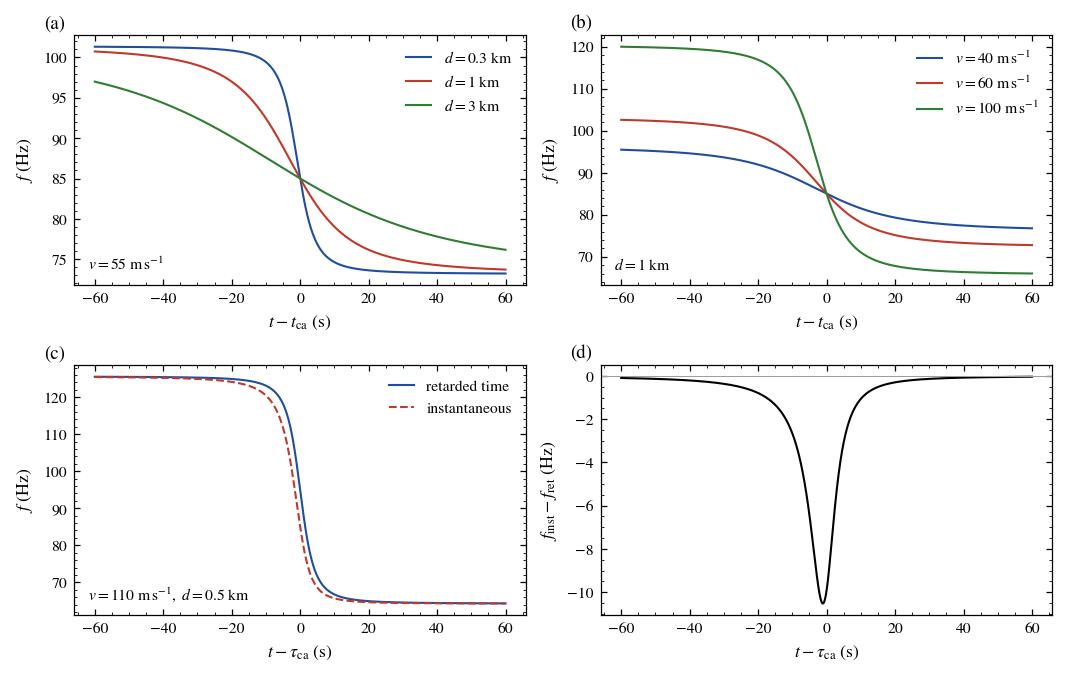

In [2]:
c15 = dg.speed_of_sound(15.0)
v, d, h = 70.0, 1200.0, 800.0
tau = np.linspace(-150, 150, 3001)
pos = np.stack([v * tau, np.full_like(tau, np.sqrt(d**2 - h**2)), np.full_like(tau, h)], -1)
vel = np.tile([v, 0.0, 0.0], (tau.size, 1))
t_arr, g, _ = dg.emission_to_arrival(tau, pos, vel, np.zeros(3), c15)
print(f"numerical vs closed form (3): max |difference| = {np.abs(g - dg.flyby_frequency(t_arr, 1.0, v, d, 0.0, c15)).max():.1e} (relative)")
t_w, g_w, _ = dg.emission_to_arrival(tau, pos, vel, np.zeros(3), c15, dg.wind_vector(8.0, 240.0))
print(f"an 8 m/s wind changes the received frequency by up to {100 * np.abs(np.interp(t_arr, t_w, g_w) - g).max():.2f} %")
show(viz.fig_doppler_model(c15), "fig1_doppler_model")

**Figure 1.** Received blade-passage frequency for a straight, level flyover with $f_0 = 85$ Hz.
(a) The slope at closest approach scales as $1/d$. (b) The frequency excursion scales with $v/c$.
(c) Retarded-time model compared with the instantaneous model, which evaluates the geometry at the arrival time.
(d) Their difference.

## 3. Synthetic scenario

A synthetic scenario is used so that the result can be compared with ground truth. All observables come from one
set of true three-dimensional trajectories, so the audio, the ADS-B feed and the truth are physically consistent.

- **Terrain and traffic.**
  - Sinusoidal terrain over a 150 × 150 km region in a local East-North-Up frame (Earth curvature included).
  - Propeller traffic with gently manoeuvring paths.
  - Two aircraft flying circuits at an aerodrome.
  - Jets at cruise altitude.
- **Audio.**
  - A receiver 1.5 m above ground records 20 min at 4 kHz.
  - Each aircraft's tone (BPF plus three harmonics, 0.3 % RPM wander) is rendered sample by sample. The received
    phase is the emitted phase at $\tau(t)$, using (1) and (4) with the *true* atmosphere.
  - The tone level includes spherical spreading, atmospheric absorption and a propeller directivity factor.
  - Background: pink and brown noise, gusty low-frequency wind noise, mains hum at 60/120/180 Hz, and broadband
    jet noise.
- **ADS-B.**
  - Reports are sampled irregularly (0.4–1.6 s apart) with occasional dropouts of 5–40 s.
  - GNSS position noise is 6 m.
  - Values are quantised as broadcast: altitude to 25 ft, ground speed to 0.1 kt, vertical rate to 64 ft min⁻¹.
- **Estimator assumptions.**
  - 10 °C and still air (the truth is 6 °C with a 6 m s⁻¹ wind).
  - A recording start time uncertain by ±15 min.

In [3]:
SEED = 7
t_start = time.perf_counter()
world = make_world(SEED)
audio = render_audio(world, seed=SEED)
adsb = synth_adsb(world, seed=SEED)
rng = np.random.default_rng(SEED + 99)              # same draw as `python -m doppler_geo demo --seed 7`
clock_error = rng.uniform(-0.6, 0.6) * 900.0
print(f"scenario generated in {time.perf_counter() - t_start:.0f} s")

n_by_class = pd.Series([tr.engine for tr in world.tracks]).map({"P": "piston", "T": "turboprop", "J": "jet"}).value_counts()
elev = world.terrain.heights
table1 = pd.DataFrame({"value": {
    "Scenario duration": f"{(world.t_end - world.t_begin) / 3600:.1f} h",
    "Aircraft (piston / turboprop / jet)": f"{n_by_class.get('piston', 0)} / {n_by_class.get('turboprop', 0)} / {n_by_class.get('jet', 0)}",
    "Terrain elevation range": f"{elev.min():.0f}–{elev.max():.0f} m",
    "Recording": f"{world.rec_duration / 60:.0f} min at {world.fs:.0f} Hz",
    "True atmosphere": f"{world.temp_c:.1f} °C (c = {world.c:.1f} m/s), wind {np.hypot(*world.wind[:2]):.1f} m/s from 240°",
    "Assumed atmosphere": f"10.0 °C (c = {dg.speed_of_sound(10):.1f} m/s), no wind",
    "ADS-B reports": f"{len(adsb):,} from {adsb.icao24.nunique()} aircraft",
    "Recording-clock prior / true offset": f"±900 s / {clock_error:+.0f} s",
}})
table1.index.name = "Table 1. Scenario"
display(table1)

scenario generated in 15 s


,value
Table 1. Scenario,
Scenario duration,3.0 h
Aircraft (piston / turboprop / jet),50 / 24 / 14
Terrain elevation range,314–528 m
Recording,20 min at 4000 Hz
True atmosphere,"6.0 °C (c = 334.9 m/s), wind 6.0 m/s from 240°"
Assumed atmosphere,"10.0 °C (c = 337.3 m/s), no wind"
ADS-B reports,"223,749 from 88 aircraft"
Recording-clock prior / true offset,±900 s / +521 s


In [4]:
truth_passes = pd.DataFrame(world.passes).rename(columns={
    "callsign": "aircraft", "t_rel": "t_ca (s)", "slant_m": "slant range (m)", "speed_ms": "speed (m/s)", "bpf_hz": "BPF (Hz)"})
truth_passes.index = [f"P{i + 1}" for i in range(len(truth_passes))]
truth_passes.index.name = "Table 2. True passes during the recording (withheld from the estimator)"
display(truth_passes[["aircraft", "type", "t_ca (s)", "slant range (m)", "speed (m/s)", "BPF (Hz)"]])

,aircraft,type,t_ca (s),slant range (m),speed (m/s),BPF (Hz)
Table 2. True passes during the recording (withheld from the estimator),,,,,,
P1,SIM501,SR22,186.79,6069.65,76.93,134.42
P2,SIM131,PC12,203.91,1496.24,112.48,103.92
P3,SIM198,C172,863.30,1802.37,52.59,84.02
P4,SIM957,SR22,910.26,5866.08,84.49,129.65


## 4. Method

### 4.1 Tonal ridge extraction

The recording is resampled to 1 kHz. A short-time Fourier transform is computed with a 2-s Hann window, 0.5-s hop
and 4× zero padding (0.125-Hz bins), restricted to 30–400 Hz. Two medians are then removed:

- each frequency bin's median over time (in dB), which suppresses stationary lines such as mains hum;
- each frame's median over frequency, which suppresses broadband transients such as wind gusts and jets.

What remains is the *spectral contrast*: how far each bin stands above its own typical level.

Ridges are traced with hysteresis:

1. A trace starts at a seed at least 11 dB above the noise.
2. It is followed forward and backward in time within a window centred on a linear prediction of the frequency.
   The window widens with the local slope.
3. Among the local maxima in the window, the one closest to the prediction is preferred. Continuity takes
   priority over amplitude, which keeps the trace on its own line where two lines cross.
4. Pixels claimed by a stronger ridge are skipped.
5. A trace stops when its running contrast falls below 6.5 dB, and fragments broken at steep sections are
   rejoined.

Ridges whose frequency ratio stays at a constant small integer are grouped as harmonics of one propeller. A group
whose Doppler fit is poor is pruned: if removing one ridge improves the fit, that ridge belonged to another
aircraft.

[audio]   1200 s of audio -> 18 tone ridges -> 11 sources -> 3 complete flyovers
[flyover] --  t=  185.3s  f0=296.71 Hz  v= 15.0 m/s  d=   155 m  rms=0.67 Hz  [at-bound]  harmonics [1]
[flyover] F1  t=  193.5s  f0=132.21 Hz  v= 85.6 m/s  d=  7403 m  rms=0.43 Hz  [ok]  harmonics [1, 2]
[flyover] F2  t=  204.1s  f0=104.25 Hz  v=114.8 m/s  d=  1570 m  rms=0.39 Hz  [ok]  harmonics [1, 2]
[flyover] --  t=  508.5s  f0=200.33 Hz  v= 15.0 m/s  d=    67 m  rms=0.53 Hz  [partial]  harmonics [1]
[flyover] --  t=  591.7s  f0=140.79 Hz  v= 15.0 m/s  d=   140 m  rms=0.71 Hz  [partial]  harmonics [1]
[flyover] --  t=  747.3s  f0=309.99 Hz  v= 15.0 m/s  d=    82 m  rms=0.64 Hz  [partial]  harmonics [1]
[flyover] F3  t=  863.5s  f0= 83.99 Hz  v= 52.2 m/s  d=  1745 m  rms=0.62 Hz  [ok]  harmonics [1, 2, 2, 3, 3, 4]
[flyover] --  t=  897.7s  f0=140.82 Hz  v= 15.7 m/s  d=    95 m  rms=0.59 Hz  [at-bound]  harmonics [1]
[flyover] --  t=  919.8s  f0=123.29 Hz  v= 61.0 m/s  d=  2343 m  rms=0.19 Hz  [partial]

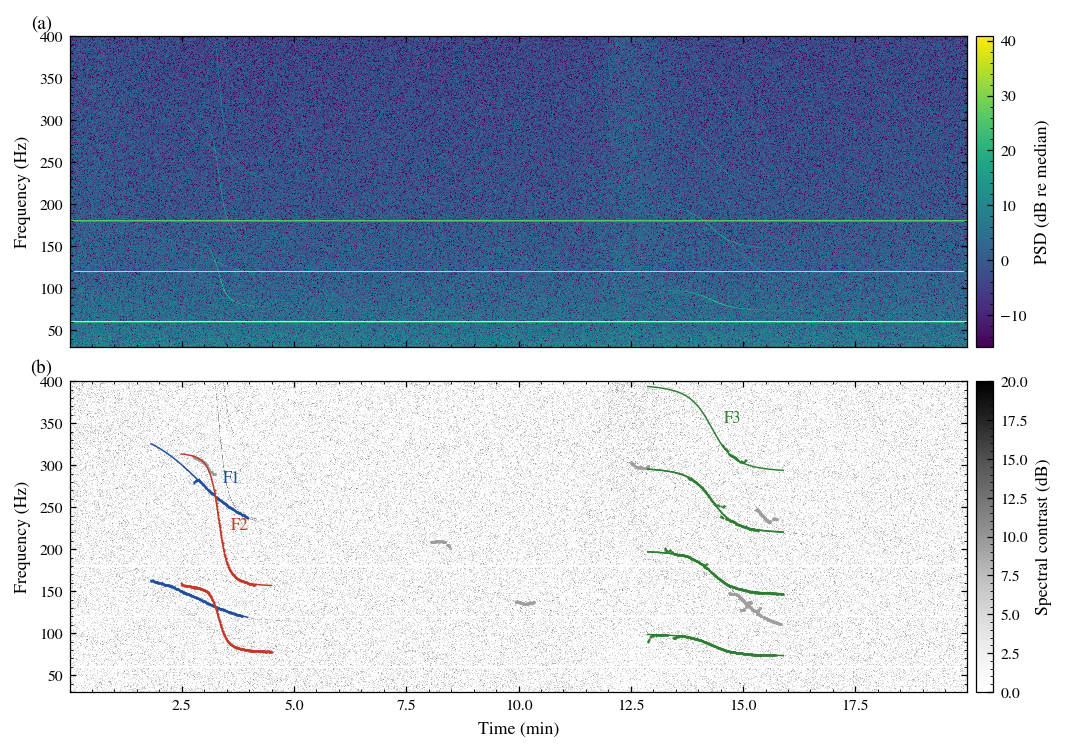

In [5]:
c_assumed = dg.speed_of_sound(10.0)
analysis = dg.analyze_audio(audio, world.fs, c_assumed)
show(viz.fig_spectrogram(analysis.spec, analysis.flyovers), "fig2_spectrogram")

**Figure 2.** (a) Power spectral density of the recording (2-s Hann window, 0.5-s hop). The horizontal lines are
mains hum. (b) Spectral contrast after median normalisation in time and frequency. Coloured markers show the traced
ridges of the usable flyovers. Lines show the fitted retarded-time model for each harmonic. Grey markers show
ridges rejected as partial, duplicated or implausible.

### 4.2 Single-flyover parameter estimation

For each harmonic group, the frequencies divided by harmonic number are fitted with (2)–(3):

- **Fit.** Robust non-linear least squares (soft-$L_1$ loss with 0.4 Hz scale), started from 15 initial guesses
  derived from the excursion, the inflection time and the slope.
- **Uncertainties.** One-sigma values from the Gauss–Newton covariance, inflated by $\sqrt{4}$. With a 2-s
  window and a 0.5-s hop, about four consecutive frames share the same samples, so they are not independent.
- **Acceptance.** A flyover is used only if all of the following hold:
  - the ridge brackets the closest approach by at least 8 s on each side;
  - the RMS residual is below 1.5 Hz;
  - no parameter sits at a bound;
  - $\sigma_d < d/2$;
  - $v > 33$ m s⁻¹, below which a light aircraft cannot be flying;
  - $d < 8$ km, the search range.

,t_ca (s),f0 (Hz),v (m/s),σ_v,d (m),σ_d,RMS (Hz),harmonics,true aircraft,true v (m/s),true d (m)
Table 3. Usable flyovers,,,,,,,,,,,
F1,193.46,132.21,85.63,2.63,7402.53,536.16,0.43,"1,2",SIM501,76.93,6069.65
F2,204.15,104.25,114.77,0.25,1570.46,14.43,0.39,"1,2",SIM131,112.48,1496.24
F3,863.46,83.99,52.15,0.59,1744.79,61.97,0.62,"1,2,2,3,3,4",SIM198,52.59,1802.37


rejected detections: partial 6, at-bound 2


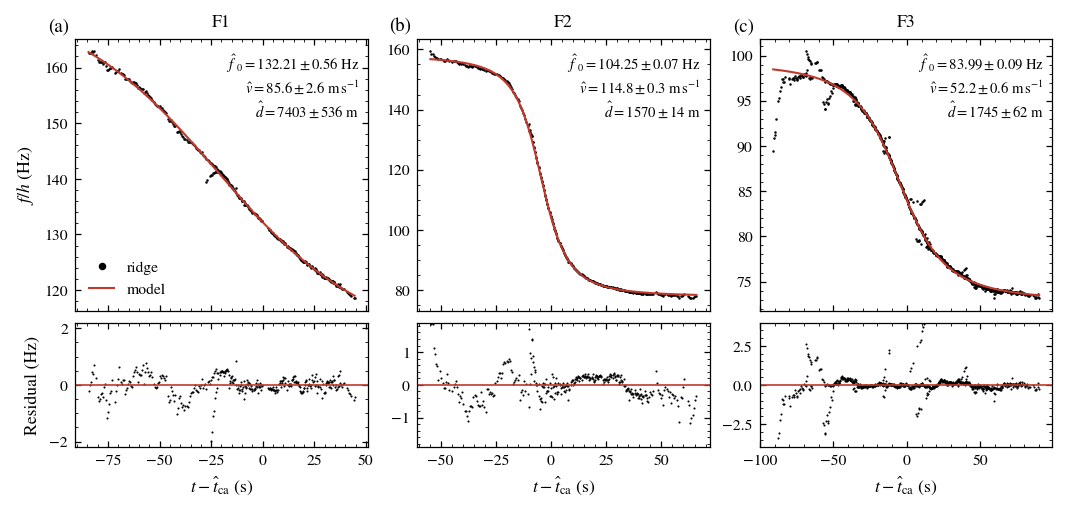

In [6]:
rows = []
for f in analysis.good:
    p = min(world.passes, key=lambda q: abs(q["t_rel"] - f.t_arr))   # evaluation only
    rows.append({"t_ca (s)": f.t_arr, "f0 (Hz)": f.f0, "v (m/s)": f.v, "σ_v": f.sigma["v"], "d (m)": f.d, "σ_d": f.sigma["d"],
                 "RMS (Hz)": f.rms_hz, "harmonics": ",".join(map(str, f.harmonics)),
                 "true aircraft": p["callsign"], "true v (m/s)": p["speed_ms"], "true d (m)": p["slant_m"]})
table3 = pd.DataFrame(rows, index=[f.name for f in analysis.good])
table3.index.name = "Table 3. Usable flyovers"
display(table3)
rejected = pd.Series([f.quality for f in analysis.flyovers if f.quality != "ok"]).value_counts()
print("rejected detections:", ", ".join(f"{k} {v}" for k, v in rejected.items()))
show(viz.fig_flyover_fits(analysis.flyovers), "fig3_flyover_fits")

**Figure 3.** Single-flyover fits. Top: ridge frequencies divided by harmonic number (dots) and the fitted
retarded-time model (line), with one-sigma parameter uncertainties. Bottom: residuals. The fit of F3 includes
fragments at its edges where the tracer briefly locked onto noise; the robust loss limits their influence.

The fitted parameters already describe each flyover's geometry, but only relative to the aircraft. Placing the
receiver requires the aircraft trajectories.

### 4.3 Trajectory reconstruction from ADS-B

Reports are converted into a single East-North-Up frame centred on the search area. ADS-B geometric altitude is
ellipsoidal, so the terrain model must use ellipsoidal heights as well.

- **Type filter.** Only piston and turboprop aircraft are kept, identified by ICAO type designator. Unknown types
  are kept too.
- **Smoothing.** Each axis is smoothed with a Rauch–Tung–Striebel smoother [4] using a constant-velocity model.
  It fuses GNSS positions ($\sigma$ = 15 m) with GNSS velocities ($\sigma$ = 0.7 m s⁻¹).
- **Resampling.** The smoothed track is resampled to 1 s with a cubic Hermite spline.
- **Gaps.** Dropouts shorter than 60 s are bridged. Longer gaps split the track, and no track is extrapolated
  across one.

In [7]:
tracks = dg.prepare_tracks(adsb, world.frame)
truth_tracks = {tr.icao24: tr for tr in world.tracks}
pos_err, vel_err = [], []
for tr in tracks:                                         # evaluation only: compare with generating trajectories
    p, v_, ok = truth_tracks[tr.icao24].state(tr.times)
    pos_err.append(np.linalg.norm(tr.pos[ok] - p[ok], axis=1))
    vel_err.append(np.linalg.norm(tr.vel[ok] - v_[ok], axis=1))
pos_err, vel_err = np.concatenate(pos_err), np.concatenate(vel_err)
print(f"reconstruction error over {len(tracks)} segments: position median {np.median(pos_err):.1f} m "
      f"(95th percentile {np.percentile(pos_err, 95):.1f} m), velocity median {np.median(vel_err):.2f} m/s "
      f"(95th percentile {np.percentile(vel_err, 95):.2f} m/s)")

[adsb]    88 aircraft in the feed, 74 propeller/unknown types -> 104 smoothed track segments
reconstruction error over 104 segments: position median 1.2 m (95th percentile 2.6 m), velocity median 0.18 m/s (95th percentile 0.43 m/s)


### 4.4 Candidate search

The search area (60 × 60 km) is divided into 200-m cells. Each cell is placed on the terrain surface in the local
frame, so slant ranges are exact in three dimensions.

**Passes.** For every track segment within the recording-time prior, every local minimum of the 3-D range to
every cell within 8 km is recorded. A parabola through the neighbouring samples refines its time and distance.
Each pass stores four quantities:

- its slant range $r$;
- its speed $s$;
- its emission time;
- its arrival time $t_\mathrm{p}$, from (1).

**Epoch consistency.** Flyovers are processed in order of increasing distance $\hat d$, closest first.

- *First flyover.* A cell is admissible if it has a pass with $0.6\hat d \le r \le 1.6\hat d$ and
  $0.8\hat v \le s \le 1.25\hat v$ (both widened by $2\sigma$), arriving inside the clock prior. That pass fixes
  the recording-clock epoch $t_0 = t_\mathrm{p} - \hat t_\mathrm{ca}$.
- *Each further flyover.* It must match a *different* pass at the same cell with
  $|t_\mathrm{p} - (t_0 + \hat t_\mathrm{ca})| \le 15$ s.

**Silence constraint.** Let $r_\mathrm{max}$ be the largest slant range among the matched passes. A cell is
rejected if another propeller aircraft passed within $r_\mathrm{max}$ while the recording was running, and no
tonal ridge was detected at that time. Such an aircraft would have been heard.

In [8]:
rec = dg.Recording(start_guess=world.rec_start + clock_error, start_unc=900.0, duration=world.rec_duration)
result = dg.locate(analysis.good, tracks, world.frame, world.terrain, rec, dg.SearchConfig(),
                   c=c_assumed, heard=analysis.heard)
table4 = pd.DataFrame([{"constraint": f[0], "cells": f[2], "hypotheses": f[3]} for f in result.funnel],
                      index=[f[1] for f in result.funnel])
table4.index.name = "Table 4. Candidate reduction"
display(table4)

[grid]    301 x 301 = 90,601 cells at 200 m; 50 prop-aircraft track segments in the time window


[passes]  1,102,529 closest approaches within 8 km (1.2 s)
[doppler] scored 61 hypotheses against the observed curves (0.2 s)


[refine]  best 0.436 Hz RMS; runner-up 1.057 Hz (2.4x worse)
[funnel]     90,601 cells    all grid cells
[funnel]     17,036 cells     18,239 hypotheses  F2 (d = 1.57 km, v = 115 m/s, t = 204 s): range, speed and epoch admissible
[funnel]        152 cells        152 hypotheses  + F3 (d = 1.74 km, v = 52 m/s, t = 863 s): consistent with a common clock epoch
[funnel]         65 cells         65 hypotheses  + F1 (d = 7.40 km, v = 86 m/s, t = 193 s): consistent with a common clock epoch
[funnel]         61 cells         61 hypotheses  silence constraint: no unheard aircraft within the matched range
[funnel]          1 cells          1 hypotheses  Doppler likelihood maximum


,constraint,cells,hypotheses
Table 4. Candidate reduction,,,
grid,all grid cells,90601,NaN
F2,"F2 (d = 1.57 km, v = 115 m/s, t = 204 s): rang...",17036,18239.0
+F3,"+ F3 (d = 1.74 km, v = 52 m/s, t = 863 s): con...",152,152.0
+F1,"+ F1 (d = 7.40 km, v = 86 m/s, t = 193 s): con...",65,65.0
silence,silence constraint: no unheard aircraft within...,61,61.0
Doppler,Doppler likelihood maximum,1,1.0


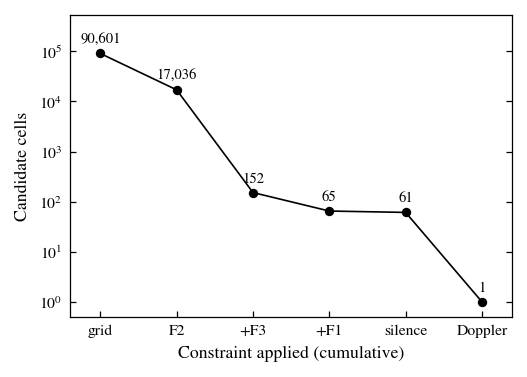

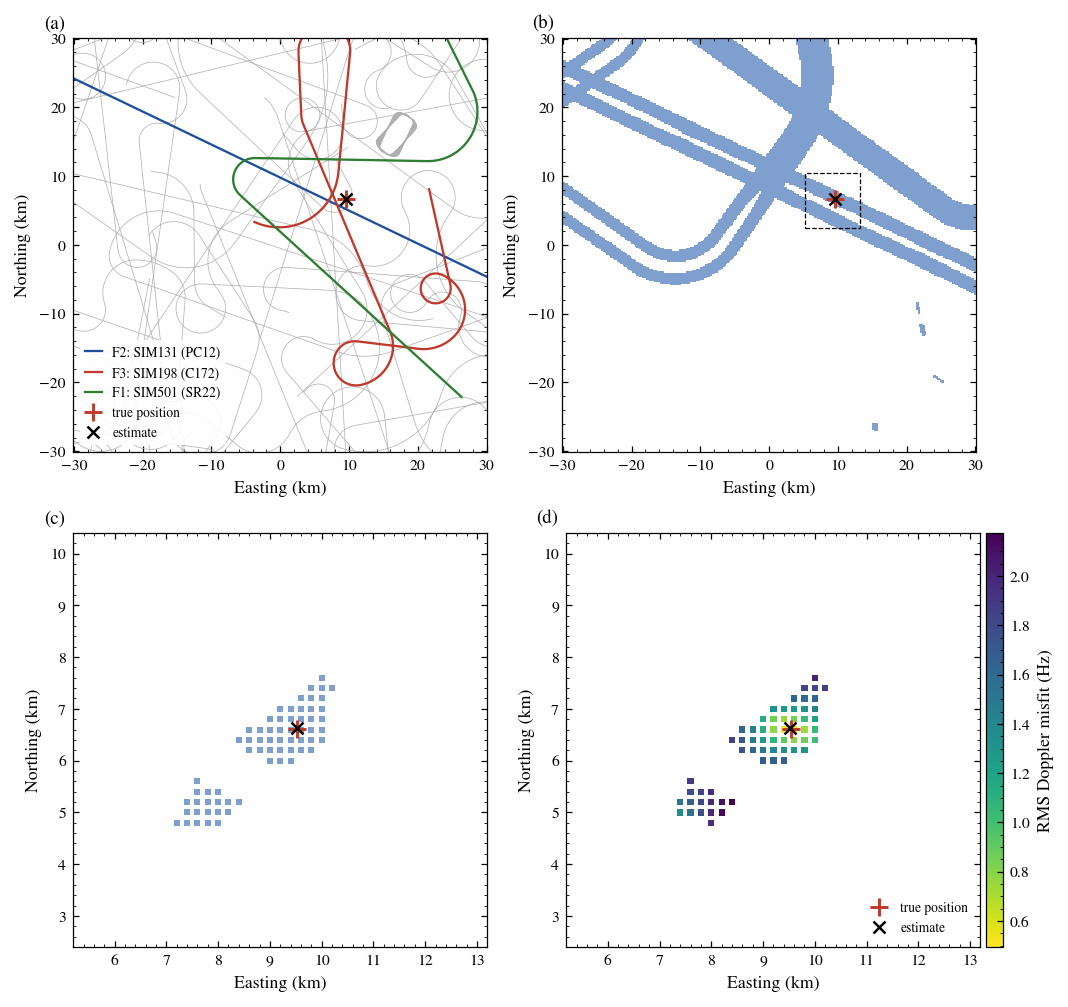

In [9]:
truth = dict(lat=world.obs_lat, lon=world.obs_lon, e=world.observer[0], n=world.observer[1])
show(viz.fig_reduction(result.funnel), "fig4_candidate_reduction")
show(viz.fig_constraints(result, truth), "fig5_spatial_constraints")

**Figure 4.** Number of candidate 200-m cells remaining after each cumulative constraint (Table 4).

**Figure 5.** Spatial constraints.
(a) Propeller-aircraft ADS-B tracks in the time window, with the tracks matched to the observed flyovers in colour.
(b) Cells admissible for the closest flyover. These form bands on either side of each track that passed within
the right distance at a plausible time. The dashed box marks the extent of (c) and (d).
(c) Cells consistent with all flyovers under a common clock epoch.
(d) Cells that survive the silence constraint, coloured by RMS Doppler misfit.

### 4.5 Doppler likelihood and refinement

For each surviving hypothesis (cell $\mathbf{x}$, epoch $t_0$, and the matched trajectory for each flyover), the
Doppler factor $g_k(t) = f/f_0$ is predicted from the reconstructed trajectory using (1) and (4). The misfit is

$$ \chi^2(\mathbf{x}, t_0) = \sum_k \sum_i w_{ki}\, \min\!\left[\left(f_{ki} - \hat f_{0,k}\, g_k(t_0 + t_{ki})\right)^2,\ (3\ \mathrm{Hz})^2\right], \tag{5} $$

with the per-flyover rest frequency solved in closed form,
$\log \hat f_{0,k} = \sum_i w_{ki}(\log f_{ki} - \log g_k)/\sum_i w_{ki}$. Truncating each term at
$(3\ \mathrm{Hz})^2$ limits the influence of outlying ridge points.

The best hypotheses are refined with the Nelder–Mead simplex method [6]. The search runs over position and
epoch, and also over a uniform wind $(w_E, w_N)$ and a sound-speed offset $\Delta c$, which are treated as
nuisance parameters with weak Gaussian priors. Approximate confidence regions follow from
$\Delta\chi^2 = 2.30$ (68 %) and $6.18$ (95 %). The residual variance is estimated at the optimum and divided by
the window/hop ratio, because neighbouring frames are correlated.

## 5. Results

### 5.1 Reference scenario

,value
Table 5. Localisation result,
Estimated position,"38.50960°, -98.09087°"
True position,"38.50955°, -98.09071°"
Horizontal error,15 m
68 % / 95 % radius (statistical),18 m / 36 m
Recording-clock error after estimation,+0.2 s (prior offset +521 s)
"RMS misfit, estimate / best alternative > 500 m away",0.436 Hz / 1.057 Hz
Fitted air temperature (true 6.0 °C),3.8 °C
Fitted wind (true 6.0 m/s from 240°),5.2 m/s from 143°
Matched aircraft,"F2→SIM131, F3→SIM198, F1→SIM501"


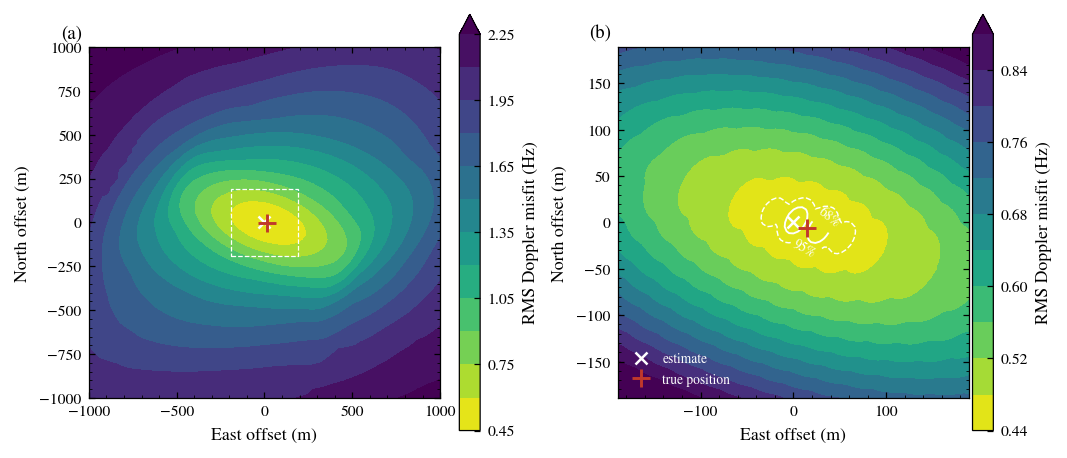

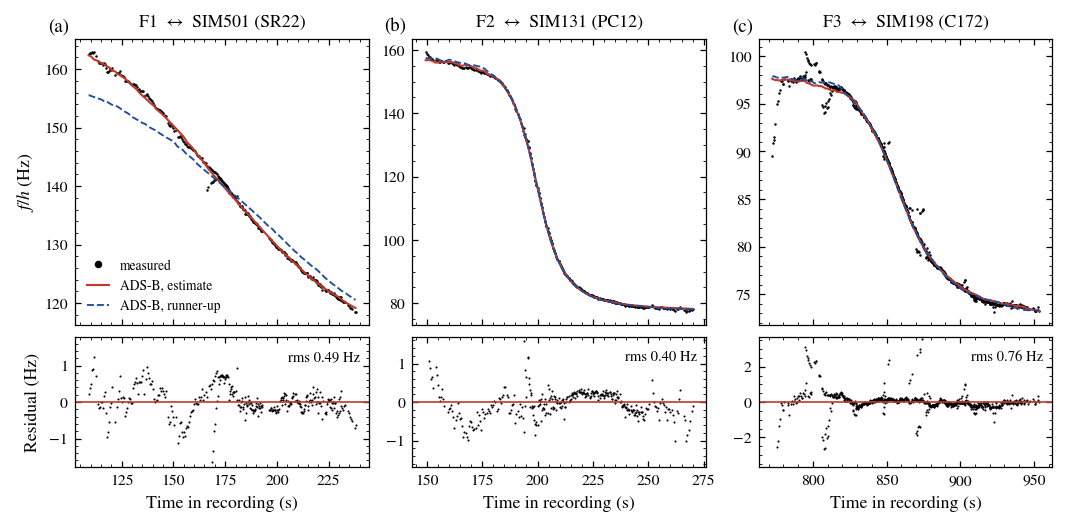

In [10]:
b = result.best
atm = atmosphere_of(b)
alt = next((cd for cd in result.candidates[1:] if np.hypot(cd["e"] - b["e"], cd["n"] - b["n"]) > 500), None)
table5 = pd.DataFrame({"value": {
    "Estimated position": f"{b['lat']:.5f}°, {b['lon']:.5f}°",
    "True position": f"{world.obs_lat:.5f}°, {world.obs_lon:.5f}°",
    "Horizontal error": f"{haversine_m(b['lat'], b['lon'], world.obs_lat, world.obs_lon):.0f} m",
    "68 % / 95 % radius (statistical)": f"{result.surface['radius68_m']:.0f} m / {result.surface['radius95_m']:.0f} m",
    "Recording-clock error after estimation": f"{b['t0'] - world.rec_start:+.1f} s (prior offset {clock_error:+.0f} s)",
    "RMS misfit, estimate / best alternative > 500 m away": f"{b['rms_hz']:.3f} Hz / {alt['rms_hz']:.3f} Hz" if alt else f"{b['rms_hz']:.3f} Hz / –",
    "Fitted air temperature (true 6.0 °C)": f"{atm['temp_c']:.1f} °C",
    "Fitted wind (true 6.0 m/s from 240°)": f"{atm['wind_ms']:.1f} m/s from {atm['wind_from_deg']:.0f}°",
    "Matched aircraft": ", ".join(f"{ev.name}→{a}" for ev, a in zip(result.events, b["aircraft"])),
}})
table5.index.name = "Table 5. Localisation result"
display(table5)
show(viz.fig_misfit_surface(result, truth), "fig6_misfit_surface")
show(viz.fig_adsb_match(result, c_assumed), "fig7_adsb_match")

**Figure 6.** RMS Doppler misfit as a function of receiver position. (a) A 2 × 2 km area around the estimate;
the dashed box marks the extent of (b). (b) Zoom with the approximate 68 % and 95 % confidence regions. These
regions reflect measurement noise only, not model error.

**Figure 7.** Measured ridge frequencies (dots) compared with those predicted from the matched ADS-B trajectories,
at the estimated position (solid) and at the best alternative more than 500 m away (dashed). Bottom: residuals at
the estimate.

The two close flyovers F2 and F3 alone leave a nearly degenerate *twin* position. At the twin, both aircraft pass
at similar distances, and both are shifted by the same number of seconds, which the free clock epoch absorbs. In
panels (b) and (c) of Fig. 7 the twin's predicted curves are almost indistinguishable from the estimate's. The
distant flyover F1 separates them: in panel (a) its predicted curve differs clearly between the two positions.

### 5.2 Monte Carlo over scenarios

The full pipeline is repeated on twelve independently generated scenarios. Each has different traffic, terrain,
receiver position and clock offset, but the same mis-specified atmosphere. This takes a few minutes.

,flyovers used,error_m,clock error (s),misfit (Hz),runner-up (Hz),ambiguous,fitted T (°C)
Table 6. Monte Carlo,,,,,,,
1,2,62.67,-0.22,0.27,0.51,False,15.62
2,3,86.88,-0.30,0.37,0.37,False,10.06
3,2,19.19,0.19,0.37,1.32,False,6.00
4,2,24.53,0.03,0.36,1.41,False,7.51
5,4,71.25,0.79,0.38,0.38,False,6.98
6,2,82.80,-1.09,0.21,0.21,False,13.38
7,3,15.17,0.23,0.44,1.06,False,3.78
8,2,27.22,0.14,0.35,0.91,False,9.23
9,4,53.10,-0.46,0.43,0.43,False,9.36


377 s | unambiguous 11/12 | error median 29 m, range 13–87 m | |clock error| max 1.1 s


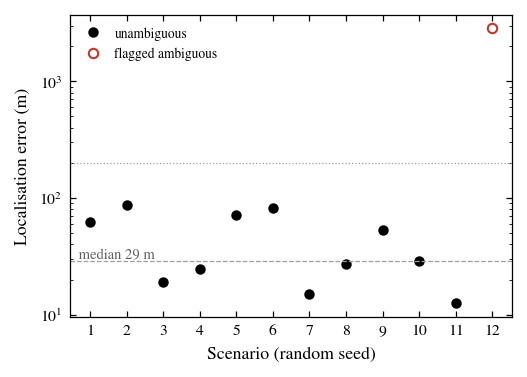

In [11]:
rows = []
t_start = time.perf_counter()
with tempfile.TemporaryDirectory() as tmp:
    for s in range(1, 13):
        r = dg.run_demo(Path(tmp) / f"s{s}", seed=s, figures=False, log=lambda *a: None)
        e = r["estimate"]
        rows.append({"seed": s, "flyovers used": len(e["matched_aircraft"]), "error_m": r["error_m"],
                     "clock error (s)": r["clock_offset_found_s"], "misfit (Hz)": e["rms_hz"],
                     "runner-up (Hz)": r["runner_ups"][0]["rms_hz"] if r["runner_ups"] else np.nan,
                     "ambiguous": e["ambiguous"], "fitted T (°C)": e["atmosphere"].get("temp_c", np.nan)})
mc = pd.DataFrame(rows).set_index("seed", drop=False)
mc.index.name = "Table 6. Monte Carlo"
display(mc.drop(columns="seed"))
ok = ~mc["ambiguous"]
print(f"{time.perf_counter() - t_start:.0f} s | unambiguous {ok.sum()}/{len(mc)} | error median {mc.error_m[ok].median():.0f} m, "
      f"range {mc.error_m[ok].min():.0f}–{mc.error_m[ok].max():.0f} m | |clock error| max {mc['clock error (s)'][ok].abs().max():.1f} s")
show(viz.fig_monte_carlo(mc), "fig8_monte_carlo")

**Figure 8.** Horizontal localisation error for twelve synthetic scenarios (logarithmic scale). Open markers show
results flagged as ambiguous, meaning another position more than 500 m away scores within 10 % of the best. The
dashed line is the median of the unambiguous cases; the dotted line marks 200 m.

## 6. Discussion and limitations

**Information content.** A single flyover fixes a slant distance and an arrival time.

- With a known clock, the receiver lies on one of two lines parallel to the track, mirror images of each other.
- With an unknown clock, it can also slide along those lines.
- A second flyover from a different direction reduces this to a few discrete solutions. These include twins whose
  timing differences the free clock epoch absorbs (§5.1).
- Three things remove twins: additional flyovers, the silence constraint, and an independent clock reference
  accurate to a few seconds.
- In the scenario flagged ambiguous in Table 6 only one usable flyover was detected. The estimator correctly
  reports the result as ambiguous rather than returning a confident wrong position.

**Error budget.** The residual errors of 10–90 m are dominated by the mis-specified atmosphere. A 1 % error in $c$
scales the inferred distances by about 1 %, and wind shifts the effective propagation speed by up to $|w|/c$.
Treating wind and $\Delta c$ as nuisance parameters absorbs part of this, but these parameters are only weakly
identifiable: the fitted temperatures in Table 6 scatter by several degrees. The confidence regions in Fig. 6
reflect measurement noise only and do not include model error.

**Detection.** The hardest cases for the tracer are fast aircraft passing close by, whose pitch changes by up to
5 Hz s⁻¹ at closest approach, and crossings between the ridges of different aircraft. A ridge that is assigned to
the wrong aircraft usually fits poorly and is rejected. Inspecting Fig. 2 nevertheless remains part of the
analysis.

**Recorded data.** Real recordings are likely to be harder than these synthetic ones:

- phone microphones and platform codecs often high-pass below roughly 100 Hz and apply automatic gain control;
- the atmosphere is stratified, which refracts sound;
- ground reflections cause interference;
- ADS-B coverage is incomplete, and some aircraft carry no transponder.

The silence constraint is only as complete as the ADS-B data behind it.

**Scope.** The method applies only when the following are available:

- propeller aircraft passing within a few kilometres;
- the recording date and approximate time;
- ADS-B coverage of those aircraft.

It does not apply to arbitrary recordings. Estimation of flight parameters from a single acoustic sensor has been
described since at least 1992 [1, 2].

## 7. Application to recorded data

The same engine runs on real data through the command line:

```bash
python -m doppler_geo analyze recording.wav --temp 12 --out out/inspect
python -m doppler_geo convert-readsb <adsb.lol tar parts> --bbox LATMIN,LATMAX,LONMIN,LONMAX --start <UTC> --end <UTC> --out flights.parquet
python -m doppler_geo locate recording.wav --adsb flights.parquet --center LAT,LON --start <UTC> --start-unc 600 --temp 12 --terrain dem.tif --geoid-offset -28
```

## References

1. B. G. Ferguson, *J. Acoust. Soc. Am.* **92** (1992), [doi:10.1121/1.403934](https://doi.org/10.1121/1.403934). Estimation of a propeller aircraft's speed and altitude from the Doppler-shifted blade-passage tone at a single microphone.
2. B. G. Ferguson and B. G. Quinn, *J. Acoust. Soc. Am.* **96** (1994), [doi:10.1121/1.410320](https://doi.org/10.1121/1.410320). Time–frequency estimation of aircraft flight parameters, including the source frequency.
3. H. H. Hubbard (ed.), *Aeroacoustics of Flight Vehicles: Theory and Practice*, NASA Reference Publication 1258 (1991).
4. H. E. Rauch, F. Tung and C. T. Striebel, "Maximum likelihood estimates of linear dynamic systems", *AIAA J.* **3**, 1445–1450 (1965).
5. adsb.lol, open ADS-B data archive (globe_history, ODbL). https://adsb.lol
6. J. A. Nelder and R. Mead, "A simplex method for function minimization", *Comput. J.* **7**, 308–313 (1965).